# Étape 2, piste 1 — HEP pendant les vidéos vs au repos

Suite de [`laura_hep_groupe.ipynb`](laura_hep_groupe.ipynb) : le HEP ne distingue pas les vidéos à activation
haute et basse. **Question ici** : le cerveau « écoute »-t-il le cœur différemment **pendant les vidéos
en général** qu'au repos ? C'est aussi la piste « comparer chacun à son propre repos » de l'étape 4.

**Comparaison principale** : vidéos (toutes) vs **repos yeux ouverts** (même état visuel : yeux ouverts).
Repos yeux ouverts = 30 s de l'enregistrement de repos + 2 × 60 s de la tâche artefact, par jour.
Le repos **yeux fermés** est montré à part : c'est un état cérébral très différent.

Mêmes participants, même nettoyage, mêmes électrodes interpolées que pour les vidéos.
Données : [`hep_group.py`](hep_group.py) (vidéos) et [`hep_repos.py`](hep_repos.py) (repos).

> **Note ajoutée après coup** : le choix des fenêtres de ce notebook a été revu dans [`laura_hep_corrections.ipynb`](laura_hep_corrections.ipynb) (test sans fenêtre de l'existence du HEP, fenêtres définies sur les conditions regroupées, latence sur toute la composante). Ce notebook est gardé tel quel pour la trace ; les conclusions ne changent pas.

In [1]:
import os
os.environ.setdefault("HABS_DATA", r"C:\Users\ehren\habs-data")   # à adapter sur ta machine

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy import stats
from hep_utils import mean_amp, frac_area_latency, peak_latency, LAT_WIN, _montage

ROOT = Path(os.environ["HABS_DATA"]) / "derivatives"
plt.rcParams["figure.dpi"] = 90
MIN_BEATS = 50
NEG, POS = (0.15, 0.32), (0.38, 0.55)    # parties négative et positive du HEP (laura_hep_groupe.ipynb)

## 1. Participants inclus

In [2]:
rv = pd.read_csv(ROOT / "hep" / "resume.csv")
rr_ = pd.read_csv(ROOT / "hep_repos" / "resume_repos.csv")
ok_v = rv[(rv.battements_basse >= MIN_BEATS) & (rv.battements_haute >= MIN_BEATS)].subj
ok_r = rr_[rr_.battements_repos_yo >= MIN_BEATS].subj
subjects = sorted(set(ok_v) & set(ok_r))
V = {s: dict(np.load(ROOT / "hep" / f"{s}.npz")) for s in subjects}
R = {s: dict(np.load(ROOT / "hep_repos" / f"{s}.npz")) for s in subjects}
f = V[subjects[0]]
times, ch_names = f["times"], [str(c) for c in f["ch_names"]]
cl_idx = [ch_names.index(str(c)) for c in f["cluster"]]
print(f"{len(subjects)} participants avec assez de battements en vidéo ET au repos yeux ouverts")
print("Exclus faute de repos :", sorted(set(ok_v) - set(ok_r)) or "aucun")
tab = rr_.set_index("subj").loc[subjects, ["battements_repos_yo", "battements_repos_yf"]]
tab["battements_videos"] = [len(V[s]["wave_cond"]) for s in subjects]
tab.describe().loc[["min", "50%", "max"]].round(0)

16 participants avec assez de battements en vidéo ET au repos yeux ouverts
Exclus faute de repos : ['P006', 'P027', 'P090', 'P165', 'P193', 'P212']


,battements_repos_yo,battements_repos_yf,battements_videos
min,57.0,59.0,222.0
50%,137.0,124.0,908.0
max,206.0,191.0,1200.0


In [3]:
def video_all(d):              # HEP toutes vidéos, pondéré par le nombre de battements
    n = {c: (d["wave_cond"] == c).sum() for c in ["basse", "moyenne", "haute"]}
    return sum(d[f"evoked_{c}"] * n[c] for c in n if f"evoked_{c}" in d) / sum(n.values())

def ecg_all(d):
    n = {c: (d["wave_cond"] == c).sum() for c in ["basse", "moyenne", "haute"]}
    return sum(d[f"ecg_{c}"] * n[c] for c in n if f"ecg_{c}" in d) / sum(n.values())

cl = lambda x: x[cl_idx].mean(0)
vid = np.array([cl(video_all(V[s])) for s in subjects])
yo = np.array([cl(R[s]["evoked_repos_yo"]) for s in subjects])
has_yf = [s for s in subjects if "evoked_repos_yf" in R[s]]
yf = np.array([cl(R[s]["evoked_repos_yf"]) for s in has_yf])

def band(ax, x, label, col, ls="-"):
    m, se = x.mean(0), x.std(0, ddof=1) / np.sqrt(len(x))
    ax.fill_between(times * 1000, m - 1.96 * se, m + 1.96 * se, color=col, alpha=.18)
    ax.plot(times * 1000, m, color=col, ls=ls, label=f"{label} (n = {len(x)})")

## 2. Les courbes
HEP fronto-central moyen du groupe (bande = IC 95 % entre participants).

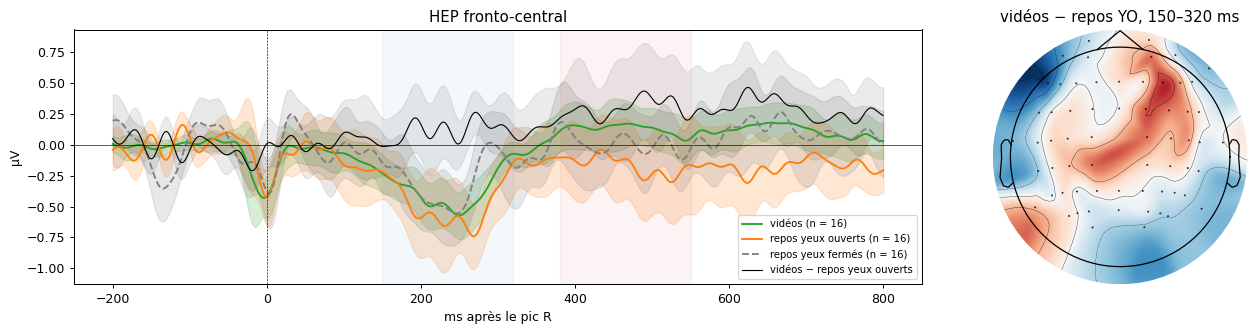

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[2, 1]))
band(axs[0], vid, "vidéos", "C2"); band(axs[0], yo, "repos yeux ouverts", "C1"); band(axs[0], yf, "repos yeux fermés", "grey", "--")
d = vid - yo; m, se = d.mean(0), d.std(0, ddof=1) / np.sqrt(len(d))
axs[0].plot(times * 1000, m, "k", lw=.9, label="vidéos − repos yeux ouverts")
axs[0].fill_between(times * 1000, m - 1.96 * se, m + 1.96 * se, color="k", alpha=.08)
for w, col in [(NEG, "C0"), (POS, "C3")]:
    axs[0].axvspan(w[0] * 1000, w[1] * 1000, color=col, alpha=.05)
axs[0].axhline(0, color="k", lw=.5); axs[0].axvline(0, color="k", lw=.5, ls="--")
axs[0].set_xlabel("ms après le pic R"); axs[0].set_ylabel("µV"); axs[0].legend(fontsize=8); axs[0].set_title("HEP fronto-central")

info = mne.create_info(ch_names, 1 / (times[1] - times[0]), "eeg"); info.set_montage(_montage(), on_missing="ignore")
diff = mne.EvokedArray(np.mean([video_all(V[s]) - R[s]["evoked_repos_yo"] for s in subjects], 0) * 1e-6, info, tmin=times[0])
diff.plot_topomap(times=[np.mean(NEG)], average=NEG[1] - NEG[0], axes=axs[1], colorbar=False, show=False)
axs[1].set_title(f"vidéos − repos YO, {NEG[0]*1000:.0f}–{NEG[1]*1000:.0f} ms")
plt.tight_layout(); plt.show()

## 3. Test principal : tout le scalp, sans fenêtre choisie à l'avance

Test de permutation par clusters (électrodes × temps, 0–600 ms) sur les différences
vidéos − repos yeux ouverts de chaque participant. Ce test ne dépend d'aucun choix de fenêtre ni
d'électrodes : c'est le résultat principal.

In [5]:
from mne.stats import permutation_cluster_1samp_test
keep = (times >= 0) & (times <= 0.6); step = 4
X = np.array([(video_all(V[s]) - R[s]["evoked_repos_yo"])[:, keep][:, ::step].T for s in subjects])
adj, _ = mne.channels.find_ch_adjacency(info, "eeg")
T, clusters, pv, _ = permutation_cluster_1samp_test(X, n_permutations=2000, adjacency=adj, seed=0,
                                                    out_type="mask", verbose=False)
tt = times[keep][::step]
print(f"{len(clusters)} clusters ; plus petit p = {pv.min() if len(pv) else float('nan'):.3f}")
sig = [i for i in np.argsort(pv) if pv[i] < 0.05]
for i in np.argsort(pv)[:3]:
    tm, chm = np.where(clusters[i]); sgn = np.sign(T[clusters[i]].mean())
    print(f"  p = {pv[i]:.3f} : {tt[tm.min()]*1000:.0f}–{tt[tm.max()]*1000:.0f} ms, {'vidéos > repos' if sgn > 0 else 'vidéos < repos'}, "
          f"{len(set(chm))} électrodes ({', '.join(sorted(set(np.array(ch_names)[chm]))[:10])})")
if sig:
    mask = clusters[sig[0]].T                                    # (électrodes, temps)
    ev_T = mne.EvokedArray(T.T, mne.create_info(ch_names, 250, "eeg"), tmin=tt[0])
    ev_T.set_montage(_montage(), on_missing="ignore")
    tm = np.where(mask.any(0))[0]
    ev_T.plot_topomap(times=[tt[tm].mean()], average=tt[tm[-1]] - tt[tm[0]] + 0.004, mask=mask,
                      units="t", scalings=1, cbar_fmt="%.1f", time_format="cluster le plus fort : %0.3f s");

C:\Users\ehren\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


33 clusters ; plus petit p = 0.350
  p = 0.350 : 432–516 ms, vidéos < repos, 12 électrodes (CP4, CP6, O2, P10, P2, P4, P6, P8, PO4, PO6)
  p = 0.571 : 540–600 ms, vidéos < repos, 5 électrodes (C4, C6, CP4, P4, PO4)
  p = 0.746 : 264–292 ms, vidéos < repos, 7 électrodes (O2, P10, P6, P8, PO4, PO6, PO8)


## 4. Tests ciblés : amplitude et latence (groupe fronto-central)

Fenêtres = parties négative (150–320 ms) et positive (380–550 ms) du HEP, définies dans l'analyse
précédente sur les vidéos. Latence : aire fractionnelle 50 % et jackknife sur les participants.

In [6]:
rows = []
for name, w in [("négative 150–320 ms", NEG), ("positive 380–550 ms", POS)]:
    dv = mean_amp(vid, times, w) - mean_amp(yo, times, w)
    t, p = stats.ttest_1samp(dv, 0)
    rows.append({"partie": name, "vidéos (µV)": mean_amp(vid, times, w).mean(), "repos YO (µV)": mean_amp(yo, times, w).mean(),
                 "différence": dv.mean(), "t": t, "p": p, "Wilcoxon p": stats.wilcoxon(dv).pvalue,
                 "participants vidéos > repos": f"{(dv > 0).sum()}/{len(dv)}"})
display(pd.DataFrame(rows).round(3))

pol = -1                                         # composante négative (cf. analyse précédente)
lat = lambda w: frac_area_latency(w, times, polarity=pol)
n = len(subjects)
full = lat(vid.mean(0)) - lat(yo.mean(0))
loo = np.array([lat(np.delete(vid, i, 0).mean(0)) - lat(np.delete(yo, i, 0).mean(0)) for i in range(n)])
se = np.sqrt((n - 1) / n * ((loo - loo.mean()) ** 2).sum())
t_jk = full / se if se > 0 else np.nan
print(f"Latence (composante négative) : vidéos {lat(vid.mean(0))*1000:.0f} ms, repos YO {lat(yo.mean(0))*1000:.0f} ms ; "
      f"différence {full*1000:+.0f} ms, ET jackknife {se*1000:.0f} ms, t_jk({n-1}) = {t_jk:.2f}, p = {2*stats.t.sf(abs(t_jk), n-1):.3f}")

,partie,vidéos (µV),repos YO (µV),différence,t,p,Wilcoxon p,participants vidéos > repos
0,négative 150–320 ms,-0.377,-0.492,0.114,1.200,0.249,0.211,12/16
1,positive 380–550 ms,0.128,-0.169,0.296,1.744,0.102,0.130,10/16


Latence (composante négative) : vidéos 250 ms, repos YO 288 ms ; différence -38 ms, ET jackknife 31 ms, t_jk(15) = -1.24, p = 0.236

## 5. Contrôles : est-ce vraiment le cerveau ?

Ici le contrôle cardiaque est **crucial** : si le cœur bat plus vite pendant les vidéos qu'au repos,
l'onde T et le battement suivant arrivent plus tôt, ce qui change la forme de l'artefact cardiaque
dans l'EEG et peut créer une fausse différence de HEP. On vérifie :
1. l'intervalle RR (vidéos vs repos) ;
2. la forme de l'ECG moyen ;
3. si la différence de HEP suit la différence de rythme cardiaque d'un participant à l'autre.

RR vidéos 875 ms, repos YO 880 ms : différence -4.6 ms, t(15) = -0.46, p = 0.650
Lien différence de RR ↔ différence de HEP (partie négative) : r = 0.29, p = 0.277
ECG moyen normalisé 150–320 ms, vidéos − repos : t(15) = -1.60, p = 0.130


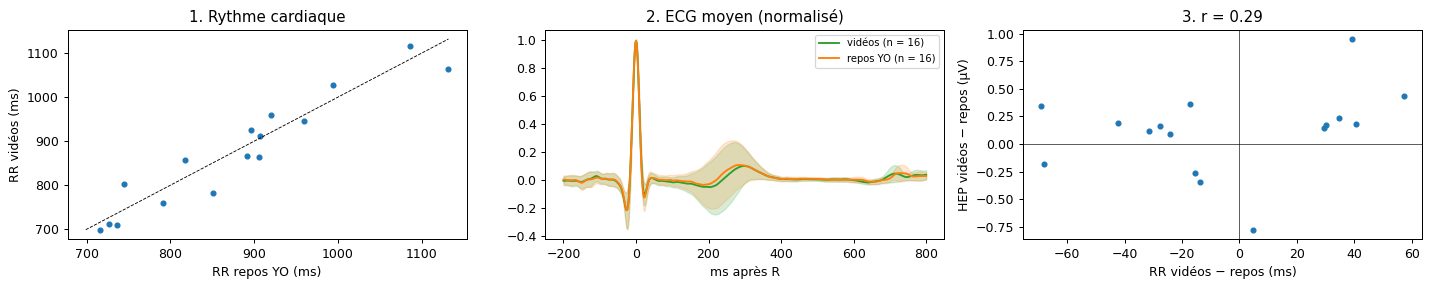

In [7]:
rr_vid = np.array([np.nanmean(V[s]["wave_rr"]) for s in subjects]) * 1000
rr_yo = rr_.set_index("subj").loc[subjects, "rr_repos_yo_s"].to_numpy() * 1000
d_rr = rr_vid - rr_yo
t, p = stats.ttest_1samp(d_rr, 0)
print(f"RR vidéos {rr_vid.mean():.0f} ms, repos YO {rr_yo.mean():.0f} ms : différence {d_rr.mean():+.1f} ms, t({len(d_rr)-1}) = {t:.2f}, p = {p:.3f}")

d_neg = mean_amp(vid, times, NEG) - mean_amp(yo, times, NEG)
r, p_r = stats.pearsonr(d_rr, d_neg)
print(f"Lien différence de RR ↔ différence de HEP (partie négative) : r = {r:.2f}, p = {p_r:.3f}")

e_v = np.array([ecg_all(V[s]) for s in subjects]); e_r = np.array([R[s]["ecg_repos_yo"] for s in subjects])
nz = lambda x: (x - x[:, (times >= -0.2) & (times <= -0.05)].mean(1, keepdims=True)) / np.abs(x).max(1, keepdims=True)
d_ecg = mean_amp(nz(e_v), times, NEG) - mean_amp(nz(e_r), times, NEG)
t, p = stats.ttest_1samp(d_ecg, 0)
print(f"ECG moyen normalisé {NEG[0]*1000:.0f}–{NEG[1]*1000:.0f} ms, vidéos − repos : t({len(d_ecg)-1}) = {t:.2f}, p = {p:.3f}")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.3))
axs[0].scatter(rr_yo, rr_vid, s=15); lim = [min(rr_yo.min(), rr_vid.min()), max(rr_yo.max(), rr_vid.max())]
axs[0].plot(lim, lim, "k--", lw=.7); axs[0].set_xlabel("RR repos YO (ms)"); axs[0].set_ylabel("RR vidéos (ms)"); axs[0].set_title("1. Rythme cardiaque")
band(axs[1], nz(e_v), "vidéos", "C2"); band(axs[1], nz(e_r), "repos YO", "C1"); axs[1].legend(fontsize=8)
axs[1].set_title("2. ECG moyen (normalisé)"); axs[1].set_xlabel("ms après R")
axs[2].scatter(d_rr, d_neg, s=15); axs[2].axhline(0, color="k", lw=.5); axs[2].axvline(0, color="k", lw=.5)
axs[2].set_xlabel("RR vidéos − repos (ms)"); axs[2].set_ylabel("HEP vidéos − repos (µV)"); axs[2].set_title(f"3. r = {r:.2f}")
plt.tight_layout(); plt.show()

## 6. Bilan

**16 participants** ont assez de battements à la fois pendant les vidéos et au repos yeux ouverts
(6 autres n'ont pas assez de repos yeux ouverts dans le dataset : P006, P027, P090, P165, P193, P212).

1. **Pas de différence significative entre vidéos et repos yeux ouverts** : aucun cluster sur le scalp
   (plus petit p = 0,35), ni sur la partie négative (+0,11 µV, p = 0,25) ou positive (+0,30 µV, p = 0,10)
   du HEP fronto-central.
2. **Une tendance, à ne pas sur-interpréter** : au repos, la composante négative semble arriver plus tard
   (288 ms contre 250 ms) et la courbe reste plus négative après 400 ms. Mais la latence n'est pas
   significative (−38 ± 31 ms, p = 0,24), et le repos est mesuré avec ~6 fois moins de battements
   (médiane 137 contre 908), donc beaucoup plus bruité.
3. **Contrôles** : rythme cardiaque identique entre vidéos et repos (RR 875 vs 880 ms, p = 0,65), et la
   différence de HEP ne suit pas la différence de rythme cardiaque (r = 0,29, p = 0,28) → rien qui puisse
   fabriquer une fausse différence.

**Comment le lire** : avec les données disponibles, le HEP ne distingue ni l'activation haute de la basse
(analyse précédente), ni les vidéos du repos. Pour l'étape 4, « comparer chacun à son propre repos » via
le HEP ne devrait pas apporter beaucoup. La tendance sur la latence pourrait mériter d'être revue avec plus
de repos (davantage de participants), mais ce n'est pas un résultat en l'état.

**Limites** :
- 16 participants seulement, et peu de repos par personne (2,5 min yeux ouverts au mieux, par jour) ;
- dans la tâche artefact, certains participants ont des fenêtres intitulées seulement « repos calme »
  (ex. P020) : comptées comme yeux ouverts, car placées au même endroit du protocole ;
- les fenêtres 150–320 / 380–550 ms viennent de l'analyse des vidéos ; le test par clusters, qui
  n'utilise aucune fenêtre, donne la même conclusion.